# **Fine-tuning d’un LLM pour la narration poétique**

> Adaptation du modèle open source *Mistral 7B* à la création littéraire, avec QLoRA.

---

## 1. Contexte et objectif

Les grands modèles de langage généralistes produisent des poèmes corrects mais souvent génériques, sans la voix propre d’un auteur. L’objectif de ce projet est de fine-tuner *Mistral 7B* sur le style de poètes célèbres comme Victor Hugo, Baudelaire ou Verlaine.

**Objectifs :**
- Construire et préparer un jeu de données de poésie.
- Fine-tuner *Mistral 7B* de manière efficace avec QLoRA.
- Évaluer qualitativement le modèle avant et après l’entraînement.

## 2. Pourquoi ce projet ?

Il s’agit de mon **premier fine-tuning de bout en bout**. Au-delà du résultat, ce projet me permet de comprendre concrètement le fonctionnement de l’adaptation des LLM : préparation des données, choix des hyperparamètres, contraintes de mémoire, évaluation et limites.

## 3. Plan du notebook

1. Installation et configuration de l’environnement.
2. Chargement du modèle de base.
3. Préparation et mise en forme du jeu de données (*dataset*).
4. Configuration de QLoRA et entraînement.
5. Évaluation et comparaison avant/après l’entraînement.
6. Sauvegarde et exportation du modèle.
7. Conclusions et pistes d’amélioration.

## 4. Avertissement

Ce projet a une vocation pédagogique. Les textes utilisés proviennent de sources libres de droits ou ouvertes. Les productions du modèle peuvent contenir des imperfections.

# 1. Installation et configuration de l'environnement

In [ ]:
%%capture
# Installation de la bibliotèque Unsloth qui accélère le fine-tuning et reduire
# fortement la consommation GPU
!pip install unsloth

In [ ]:
#Vérification de l'environnement de travail
import torch
print("Pytorch Version : ", torch.__version__)

if torch.cuda.is_available() :
    print("GPU : ", torch.cuda.get_device_name(0))
    print(f"VRAM (Mémoire vidéo) : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} Go")
else :
  print("Pas de GPU disponible")

Pytorch Version :  2.11.0+cu130
GPU :  Tesla T4
VRAM (Mémoire vidéo) : 14.6 Go


# 2. Chargement du modèle

In [ ]:
from unsloth import FastLanguageModel

max_seq_length = 2048 #Ceci est la taille maximale d'un exemple (token)

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/mistral-7b-instruct-v0.3-bnb-4bit",
    max_seq_length = max_seq_length,
    dtype = None,    #On laisse Unsloth détecter automatique le type de donnée pour le GPU
    load_in_4bit = True, #Reduire la taille du modèle
)

print("Modèle chargé")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.7: Fast Mistral patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Modèle chargé


## Test avant entrainement pour voir le comportement du modèle

In [ ]:
message = [{"role" : "user", "content" : "Ecris un poème sur la nature dans le style de Victor Hugo"}]

inputs = tokenizer.apply_chat_template(
    message,
    tokenize = True,
    add_generation_prompt = True,
    return_tensors = "pt"
).to("cuda")

outputs = model.generate(
    input_ids = inputs,
    max_new_tokens = 300,
    temperature = 0.7,
    do_sample = True,
)

response = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(response)

Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Ecris un poème sur la nature dans le style de Victor Hugo Sur les monts sombres et brumeux où rêvent les dieux,

Où le vent hurle et les arbres pleurent leurs souffrances,

La nature, ma mère, s'écoule et s'écume sous mes pieds,

Et je vois en elle une épopée plus belle que les romances.

L'aube, pâle lumière, se lève dans les cieux bleus et froids,

Et la nuit, comme frère, me regarde avec ses yeux noirs.

Je les aime tous, cet amour grandissant chaque jour,

Un amour qui me plonge dans le rêve et me fait sourire et pleurer.

Dans les forêts sombres, je m'enfonce jusqu'au fond,

Et je vois en ces arbres les mots d'une langue plus ancienne.

Ils parlent de temps passés, de mondes inaccessibles,

Et je les entends, leur parler de ce monde qui m'appartient.

Je marche dans les bois, je suis un simple berger,

Qui chante sur le chemin ses chansons d'amour et de rêves.



# Critique et Évaluation

## 1. Diagnostic global

Le poème montre un bel enthousiasme romantique et une réelle sensibilité envers la nature, ce qui s'accorde très bien avec l'esprit de Victor Hugo. Toutefois, pour se rapprocher de la poésie classique du XIXᵉ siècle, plusieurs erreurs de langue ainsi que des écarts par rapport aux règles de la métrique doivent être corrigés. Sans oublier aussi le faite que le modèle à commencer par répondre en reécrivant la consigne


## 2. Erreurs de langue (Orthographe, Conjugaison et Lexique)

* **« L'âme s'enfoule »**
  * **Problème :** Le verbe *s'enfouler* n'existe pas en français.
  * **Correction suggérée :** *« L'âme s'envole »* ou *« L'âme s'enfuit »*.

* **« Quand l'hiver répétit »**
  * **Problème :** Faute de conjugaison sur le verbe *répéter*.
  * **Explication :** Au présent de l'indicatif, la forme correcte est *répète*. Au passé simple, ce serait *répéta*.
  * **Correction suggérée :** *« Quand l'hiver répète »*.

* **« Pose sur chaque feuille, sur chaque fleur, ses flairs »**
  * **Problème :** Impropriété lexicale. Le mot *flair* désigne l'odorat.
  * **Explication :** Utiliser *flair* pour parler de rayons ou de la clarté du soleil crée une confusion de sens.
  * **Correction suggérée :** *« ses feux »*, *« ses clartés »* ou *« ses rayons »*.

* **« Resent le souffle divin »**
  * **Problème :** Faute d'orthographe.
  * **Explication :** Le verbe *ressentir* prend deux « s ».
  * **Correction suggérée :** *« Ressent »*.

---

## 3. Analyse de la métrique et du style classique

Victor Hugo utilisait principalement l'**alexandrin** (vers de 12 syllabes avec une césure au milieu) et des schémas de rimes stricts (*AABB*, *ABAB*, ou *ABBA*).

1. **Métrique variable :**
   * Les vers contiennent entre 10 et 16 syllabes.
   * *Exemple :* `Oui, la Na-ture, la Gran-de Mè-re, est sub-li-me et bel-le` = 15/16 syllabes.
2. **Qualité et régularité des rimes :**
   * Certains vers ne riment pas ensemble (*plaisir* / *partager*, *anime* / *fin*).
   * L'alternance des rimes féminines (finissant par un *-e* muet) et masculines n'est pas respectée.
3. **Répétitions lexicales :**
   * Le mot « fleur » apparaît trois fois de manière très rapprochée (vers 6, vers 8, vers 13).

---

## 4. Proposition de réécriture (Style Alexandrin Hugolien)

Voici une version remaniée respectant la métrique classique en **alexandrins (12 syllabes)** avec rimes régulières :

> Dans les grands bois profonds aux secrets éternels,  
> Où l'arbre parle au vent sous les sombres nacelles,  
> L'âme cherche l'essor comme l'oiseau des cieux,  
> Quand l'hiver vient étendre un voile silencieux.  
>  
> Mais le beau mai revient, tendre et plein de lumière,  
> Faisant fleurir le champ et réveillant la terre ;  
> Et le soleil d'or pur, sortant de son sommeil,  
> Pose un rayon béni sur le monde vermeil.  
>  
> La nature est auguste, immortelle et vivante,  
> Elle offre au voyageur sa musique enchantée ;  
> Chaque arbre et chaque fleur sous le ciel lumineux  
> Ressent le souffle saint du Grand Dieu majestueux.



## 3. Préparation du jeu de données
Source : **Project Gutenberg** (textes du domaine public).

Poètes : Victor Hugo, Charles Baudelaire, Paul Verlaine.

### Étape 1 : Téléchargement des œuvres depuis Project Gutenberg

Cette première étape consiste à récupérer automatiquement les textes bruts des poètes cibles (Baudelaire, Hugo, Verlaine) directement depuis la plateforme Project Gutenberg, puis à nettoyer les en-têtes et pieds de page légaux spécifiques à la plateforme pour ne conserver que l'œuvre littéraire pure.

In [ ]:
import os
import re
import time
import requests

os.makedirs("data/raw", exist_ok=True)

# nom du fichier -> (numéro d'ebook Gutenberg, auteur)
SOURCES = {
    "baudelaire_fleurs_du_mal":       (6099,  "Baudelaire"),
    "hugo_contemplations_autrefois":  (29843, "Hugo"),
    "hugo_contemplations_aujourdhui": (29844, "Hugo"),
    "hugo_legende_siecles_t1":        (72885, "Hugo"),
    "hugo_legende_siecles_t2":        (76396, "Hugo"),
    "verlaine_oeuvres_completes_v1":  (15112, "Verlaine"),
}

def telecharger(ebook_id):
    url = f"https://www.gutenberg.org/ebooks/{ebook_id}.txt.utf-8"
    r = requests.get(url, headers={"User-Agent": "projet-pedagogique-finetuning"}, timeout=60)
    r.raise_for_status()
    r.encoding = "utf-8"
    return r.text

def retirer_licence(texte):
    """Retire l'en-tête et le pied de page légaux de Gutenberg."""
    texte = texte.replace("\r\n", "\n").lstrip("\ufeff")
    fin = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK.*", texte)
    if fin:
        texte = texte[:fin.start()]
    debut = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", texte)
    if debut:
        texte = texte[debut.end():]
    return texte.strip()

for nom, (ebook_id, auteur) in SOURCES.items():
    brut = telecharger(ebook_id)
    propre = retirer_licence(brut)
    with open(f"data/raw/{nom}.txt", "w", encoding="utf-8") as f:
        f.write(propre)
    print(f"{nom:35s} {auteur:11s} {len(propre):>9,} caractères")
    time.sleep(1)  # politesse envers le serveur

baudelaire_fleurs_du_mal            Baudelaire    155,436 caractères
hugo_contemplations_autrefois       Hugo          227,866 caractères
hugo_contemplations_aujourdhui      Hugo          285,543 caractères
hugo_legende_siecles_t1             Hugo          314,737 caractères
hugo_legende_siecles_t2             Hugo          386,175 caractères
verlaine_oeuvres_completes_v1       Verlaine      264,687 caractères


### Étape 2 : Inspection visuelle des données brutes

Avant de procéder à tout traitement automatique, il est indispensable de faire une rapide inspection visuelle de la structure des fichiers téléchargés (début et milieu du texte) afin de comprendre comment sont structurés les poèmes, les strophes, et de repérer les éventuels bruits textuels restants (tables des matières, métadonnées de numérisation).

In [ ]:
for nom in SOURCES:
    with open(f"data/raw/{nom}.txt", encoding="utf-8") as f:
        lignes = f.read().split("\n")
    milieu = len(lignes) // 2
    print("=" * 70)
    print(f"{nom} : {len(lignes)} lignes")
    print("--- DÉBUT ---")
    print("\n".join(lignes[:15]))
    print("--- MILIEU ---")
    print("\n".join(lignes[milieu:milieu + 25]))

baudelaire_fleurs_du_mal : 4963 lignes
--- DÉBUT ---
Produced by Tonya Allen, Julie Barkley, Juliet Sutherland,
Charles Franks and the Online Distributed Proofreading Team.












LES FLEURS DU MAL
--- MILIEU ---
  Comme un râle d'agonisant.
  J'aspire, volupté divine!

  Hymne profond, délicieux!
  Tous les sanglots de ta poitrine,
  Et crois que ton coeur s'illumine
  Des perles que versent tes yeux!

  Je sais que ton coeur, qui regorge
  De vieux amours déracinés,
  Flamboie encor comme une forge,
  Et que tu couves sous ta gorge
  Un peu de l'orgueil des damnés;

  Mais tant, ma chère, que tes rêves
  N'auront pas reflété l'Enfer,
  Et qu'en un cauchemar sans trêves,
  Songeant de poisons et de glaives,
  Eprise de poudre et de fer,

  N'ouvrant à chacun qu'avec crainte,
  Déchiffrant le malheur partout,
  Te convulsant quand l'heure tinte,
  Tu n'auras pas senti l'étreinte
  De l'irrésistible Dégoût,
hugo_contemplations_autrefois : 6603 lignes
--- DÉBUT ---
Produced by Adria

### Étape 3 : Structuration, découpage et filtrage des poèmes

Pour pouvoir entraîner notre modèle, nous devons découper ces immenses fichiers textes en unités d'apprentissage adaptées (des poèmes individuels ou des extraits de longueur raisonnable). Ce code utilise des expressions régulières pour identifier les titres, ignorer les chiffres romains, vérifier que les lignes ressemblent bien à du vers (détection des majuscules en début de ligne), et découper les poèmes trop longs en extraits de 4 à 48 lignes afin de ne pas dépasser la mémoire du GPU.

In [ ]:
import re
import random
from collections import Counter

MAX_LIGNES = 48   # longueur maximale d'un extrait (en vers)
MIN_LIGNES = 4    # on ignore les textes trop courts

ROMAIN = re.compile(r"^[IVXLC]+\.?$")

def en_blocs(texte):
    """Découpe le texte en strophes (blocs séparés par des lignes vides)."""
    texte = re.sub(r"\[(Illustration|Note|Footnote)[^\]]*\]", "", texte)
    blocs, courant = [], []
    for ligne in texte.split("\n"):
        ligne = ligne.strip()
        if ligne:
            courant.append(ligne)
        elif courant:
            blocs.append(courant)
            courant = []
    if courant:
        blocs.append(courant)
    return blocs

def est_romain(bloc):
    return len(bloc) == 1 and bool(ROMAIN.match(bloc[0]))

def est_titre(bloc):
    """Un titre : 1-2 lignes courtes, entièrement en majuscules."""
    if len(bloc) > 2 or any(len(l) > 60 for l in bloc):
        return False
    lettres = [c for c in " ".join(bloc) if c.isalpha()]
    return len(lettres) >= 3 and all(c.isupper() for c in lettres)

def ressemble_a_du_vers(lignes):
    """Dans ces recueils, presque chaque vers commence par une majuscule ;
    dans de la prose (préfaces), très peu de lignes le font."""
    debuts = []
    for l in lignes:
        m = re.search(r"[A-Za-zÀ-ÿ]", l)
        if m:
            debuts.append(m.group(0).isupper())
    return len(debuts) > 0 and sum(debuts) / len(debuts) >= 0.8

def decouper_en_poemes(texte):
    poemes, strophes, titre = [], [], None

    def clore():
        nonlocal strophes, titre
        if strophes:
            poemes.append((titre, strophes))
        strophes, titre = [], None

    for bloc in en_blocs(texte):
        if est_romain(bloc):
            clore()
        elif est_titre(bloc):
            if strophes:
                clore()
            titre = " ".join(bloc).capitalize()
        else:
            strophes.append(bloc)
    clore()
    return poemes

def en_extraits(strophes):
    """Coupe les poèmes trop longs en extraits, toujours entre deux strophes."""
    extraits, courant, n = [], [], 0
    for s in strophes:
        if courant and n + len(s) > MAX_LIGNES:
            extraits.append(courant)
            courant, n = [], 0
        courant.append(s)
        n += len(s)
    if courant:
        extraits.append(courant)
    return extraits

def construire(nom, auteur):
    with open(f"data/raw/{nom}.txt", encoding="utf-8") as f:
        texte = f.read()
    resultat = []
    for titre, strophes in decouper_en_poemes(texte):
        for i, ext in enumerate(en_extraits(strophes)):
            lignes = [l for s in ext for l in s]
            if len(lignes) < MIN_LIGNES or not ressemble_a_du_vers(lignes):
                continue
            resultat.append({
                "auteur": auteur,
                "source": nom,
                "titre": titre if i == 0 else None,
                "texte": "\n\n".join("\n".join(s) for s in ext),
            })
    return resultat

poemes = []
for nom, (_, auteur) in SOURCES.items():
    poemes += construire(nom, auteur)

# --- Statistiques ---
print("Nombre de textes par auteur :", dict(Counter(p["auteur"] for p in poemes)))
print("Nombre de textes par source :")
for nom, n in Counter(p["source"] for p in poemes).items():
    print(f"  {nom:35s} {n}")

# --- Quelques exemples à vérifier à l'œil ---
random.seed(42)
for auteur in ["Hugo", "Baudelaire", "Verlaine"]:
    for p in random.sample([x for x in poemes if x["auteur"] == auteur], 2):
        print("=" * 60)
        print(f"[{auteur}] titre : {p['titre']}  (source : {p['source']})")
        print(p["texte"][:400])

Nombre de textes par auteur : {'Baudelaire': 137, 'Hugo': 759, 'Verlaine': 301}
Nombre de textes par source :
  baudelaire_fleurs_du_mal            137
  hugo_contemplations_autrefois       155
  hugo_contemplations_aujourdhui      195
  hugo_legende_siecles_t1             185
  hugo_legende_siecles_t2             224
  verlaine_oeuvres_completes_v1       301
[Hugo] titre : La défiance d'onfroy  (source : hugo_legende_siecles_t2)
Parmi les noirs déserts et les mornes silences,
Ratbert, pour l'escorter, n'ayant que quelques lances,
Et le marquis Sénèque et l'évêque Afranus,
Traverse, presque seul, des pays inconnus;
Mais il sait qu'il est fort de l'effroi qu'il inspire,
Et que l'empereur porte avec lui tout l'empire.
Un soir Ratbert s'arrête aux portes de Carpi;
Sur ce seuil formidable un dogue est accroupi;
Ce dogue, c'est
[Hugo] titre : Chose vue un jour de printemps  (source : hugo_contemplations_autrefois)
Entendant des sanglots, je poussai cette porte.

Les quatre enfants pleuraien

### Étape 4 : Rééquilibrage du jeu de données

Comme Victor Hugo est extrêmement prolifique par rapport à Baudelaire et Verlaine dans notre sélection, le jeu de données initial est très déséquilibré. Pour éviter que le modèle final ne soit biaisé et n'adopte que le style de Hugo, nous appliquons ici un plafond de 300 extraits maximum par auteur.

In [ ]:
PLAFOND_PAR_AUTEUR = 300
random.seed(42)

equilibre = []
for auteur in ["Hugo", "Baudelaire", "Verlaine"]:
    lot = [p for p in poemes if p["auteur"] == auteur]
    random.shuffle(lot)
    equilibre += lot[:PLAFOND_PAR_AUTEUR]

print("Après rééquilibrage :", dict(Counter(p["auteur"] for p in equilibre)))

Après rééquilibrage : {'Hugo': 300, 'Baudelaire': 137, 'Verlaine': 300}


### Étape 5 : Génération des thèmes d'entraînement par ingénierie de prompt

Afin de pouvoir demander plus tard au modèle d'écrire sur un thème précis (ex: "la mer"), nous devons annoter chaque extrait de notre jeu de données avec son sujet principal. Nous exploitons ici les capacités d'analyse de Mistral 7B en mode "Zero-Shot" pour résumer chaque poème en un court groupe nominal de 3 à 8 mots.

In [ ]:
import torch
from tqdm.auto import tqdm

tokenizer.padding_side = "left"          # nécessaire pour générer par lots
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

CONSIGNE_THEME = (
    "Voici un extrait de poème :\n\n{extrait}\n\n"
    "Indique le sujet de ce poème par un court groupe nominal français de 3 à 8 mots "
    "(exemple : la mort d'une mère pauvre). Réponds uniquement par ce groupe nominal."
)

def extrait_court(texte, n=12):
    lignes = [l for l in texte.split("\n") if l.strip()]
    return "\n".join(lignes[:n])

def nettoyer_theme(brut):
    t = brut.strip().split("\n")[0].strip(" \"'«»“”.")
    t = re.sub(r"^(sujet|thème)\s*:\s*", "", t, flags=re.I)
    if not (3 <= len(t) <= 80):
        return None
    return t[0].lower() + t[1:]

def generer_themes(liste, batch_size=8):
    for i in tqdm(range(0, len(liste), batch_size)):
        lot = liste[i:i + batch_size]
        prompts = [
            tokenizer.apply_chat_template(
                [{"role": "user", "content": CONSIGNE_THEME.format(extrait=extrait_court(p["texte"]))}],
                tokenize=False,
                add_generation_prompt=True,
            )
            for p in lot
        ]
        enc = tokenizer(prompts, return_tensors="pt", padding=True,
                        add_special_tokens=False).to("cuda")
        with torch.no_grad():
            sortie = model.generate(**enc, max_new_tokens=30, do_sample=False,
                                    pad_token_id=tokenizer.pad_token_id)
        for p, ids in zip(lot, sortie):
            brut = tokenizer.decode(ids[enc["input_ids"].shape[1]:], skip_special_tokens=True)
            p["theme"] = nettoyer_theme(brut)

generer_themes(equilibre)

# --- Contrôle qualité ---
manquants = sum(p["theme"] is None for p in equilibre)
print(f"Sujets manquants : {manquants} / {len(equilibre)}")
for p in random.sample(equilibre, 10):
    premier_vers = p["texte"].split("\n")[0]
    print(f"[{p['auteur']}] {p['theme']}   ←   {premier_vers}")

  0%|          | 0/93 [00:00<?, ?it/s]

Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Sujets manquants : 45 / 737
[Hugo] le sujet du poème est : le capitaine de Gaiffier   ←   Qu'est-ce que Gaïffer? La fauve dynastie
[Hugo] lumière divine, révélation de l'Indra   ←   Le dieu s'en revint.
[Hugo] le sujet du poème est Jean à Patmos   ←   Un jour, le morne esprit, le prophète sublime
[Verlaine] None   ←   _A Louis-Xavier de Ricard._
[Baudelaire] l'amour nocturne, la nuit, l'amant brun   ←   Comme les anges à l'oeil fauve,
[Verlaine] None   ←   La lune est rouge au brumeux horizon;
[Verlaine] sages d'autrefois, astres, Saturne, nécromanciens, grimoires anciens, malheur   ←   _Les Sages d'autrefois, qui valaient bien ceux-ci,
[Hugo] l'ouragan, la création   ←   Tout est la mort, l'horreur, la guerre;
[Verlaine] fête aux sept péchés des démons adolescents dans un palais de soie et or   ←   _A Villiers de l'Isle-Adam._
[Verlaine] l'automne de mon coeur   ←   Les sanglots longs


### Étape 6 : Nettoyage fin et filtrage des sujets générés

Les réponses générées automatiquement par un LLM peuvent parfois être verbeuses, répétitives ou mal formatées. Cette cellule applique des filtres stricts pour nettoyer les thèmes (suppression des préfixes de type "Le sujet est :", suppression des dédicaces de théâtre encombrantes) et ne conserver que les extraits associés à un thème de haute qualité.

In [ ]:
DEDICACE = re.compile(r"^_[AÀ]\s+[^,;:!?]{3,60}\._$")
DETERMINANTS = {"le", "la", "les", "l", "un", "une", "des", "du", "de", "d", "ce", "cet",
                "cette", "mon", "ma", "mes", "son", "sa", "ses", "notre", "nos", "leur", "leurs"}

def nettoyer_texte(texte):
    """Retire la dédicace éventuelle en tête et les tirets bas d'italique."""
    lignes = texte.split("\n")
    if lignes and DEDICACE.match(lignes[0].strip()):
        lignes = lignes[1:]
    return "\n".join(lignes).replace("_", "").strip()

def nettoyer_theme(brut):
    t = brut.strip().split("\n")[0].strip(" \"'«»“”.")
    t = re.sub(r"^(le\s+)?(sujet|thème)(\s+du\s+poème)?(\s+est)?\s*:?\s*", "", t, flags=re.I)
    t = t.strip(" \"'«»“”.")
    if not (3 <= len(t) <= 80) or t.count(",") > 1 or len(t.split()) > 10:
        return None
    if re.match(r"^(ce|cet)\s+(poème|extrait)", t, re.I):
        return None
    # minuscule initiale seulement pour les noms communs (pas pour "Jean à Patmos")
    if re.split(r"[\s']", t, maxsplit=1)[0].lower() in DETERMINANTS:
        t = t[0].lower() + t[1:]
    return t

# Consigne améliorée (la fonction generer_themes utilise cette variable)
CONSIGNE_THEME = (
    "Voici un extrait de poème :\n\n{extrait}\n\n"
    "Donne le sujet principal de ce poème sous la forme d'un seul groupe nominal français "
    "de 3 à 8 mots, sans liste et sans phrase. "
    "Exemples : la mort d'une mère pauvre ; un voyage en mer ; la tristesse de l'automne. "
    "Réponds uniquement par ce groupe nominal."
)

# 1. Nettoyage des textes ; si le texte change, on régénère son sujet
for p in equilibre:
    avant = p["texte"]
    p["texte"] = nettoyer_texte(avant)
    if p["texte"] != avant:
        p["theme"] = None
    else:
        p["theme"] = nettoyer_theme(p["theme"]) if p.get("theme") else None

equilibre = [p for p in equilibre if p["texte"].count("\n") + 1 >= MIN_LIGNES]

# 2. Régénération des sujets manquants ou rejetés
a_refaire = [p for p in equilibre if p["theme"] is None]
print(f"Sujets à (re)générer : {len(a_refaire)}")
generer_themes(a_refaire)

# 3. On écarte ce qui n'a toujours pas de sujet valable
equilibre = [p for p in equilibre if p["theme"] is not None]
print("Textes conservés :", len(equilibre), dict(Counter(p["auteur"] for p in equilibre)))

# 4. Contrôle visuel sur les sujets régénérés
refaits = [p for p in a_refaire if p["theme"]]
for p in random.sample(refaits, min(10, len(refaits))):
    print(f"[{p['auteur']}] {p['theme']}   ←   {p['texte'].split(chr(10))[0]}")

Sujets à (re)générer : 255


  0%|          | 0/32 [00:00<?, ?it/s]

Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=30) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Textes conservés : 630 {'Hugo': 263, 'Baudelaire': 124, 'Verlaine': 243}
[Hugo] Enfance heureuse entre Montlignon et Saint-Leu   ←   O souvenirs! printemps! aurore!
[Verlaine] l'oubli sous l'influence de l'alcool (l'eau-de-vie)   ←   A Raoul Ponchon.
[Verlaine] l'obligation de l'amour réciproque entre Chloris et Myrtil   ←   La vérité m'oblige...
[Verlaine] l'indifférence à l'action vilaine   ←   Fi! l'action vilaine! Au moins rougissez d'elle!
[Verlaine] l'amour divin, la peur de l'innocence   ←   --Seigneur, c'est trop? Vraiment je n'ose. Aimer qui? Vous?
[Hugo] la joie de la nature printanière   ←   Le firmament est plein de la vaste clarté;
[Verlaine] Travail humble et ennuyeux, amour nécessaire   ←   La vie humble aux travaux ennuyeux et faciles
[Verlaine] Premier amour d'une jeune femme   ←   La vision cessa.
[Verlaine] l'arrivée de Rosalinde ; le serment de Myrtil   ←   ROSALINDE, survenant.
[Baudelaire] la dégradation morale de l'individu   ←   La sottise, l'erreur, le péché, l

### Étape 7 : Filtrage par longueur de tokens et analyse de la distribution

Nous calculons ici la longueur en tokens de chaque extrait restant afin de s'assurer qu'aucun ne dépasse la taille maximale supportée par notre contexte d'entraînement, et nous visualisons la distribution de ces longueurs pour chaque auteur sous forme d'histogramme.

Retirés : 0 | conservés : 572 {'Hugo': 238, 'Baudelaire': 124, 'Verlaine': 210}
Premières lignes à vérifier : []


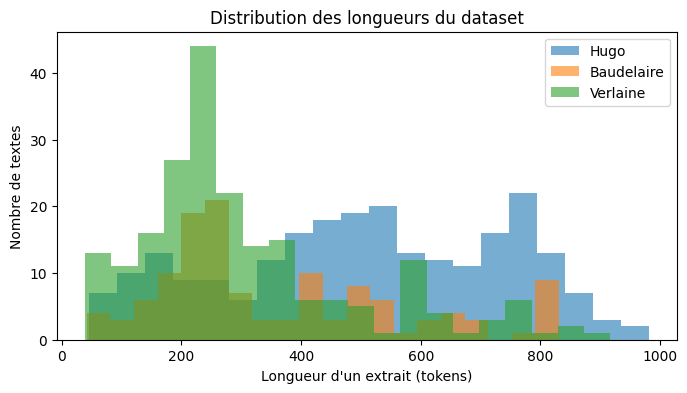

Longueur max : 981 tokens (limite : 2048 )


In [ ]:
import matplotlib.pyplot as plt

# Dédicace : tirets bas facultatifs, mais un nom propre est obligatoire ("A Raoul Ponchon.")
DEDICACE = re.compile(r"^_?[AÀ]\s+[A-ZÉÈ][^,;:!?]{2,60}\._?$")
# Réplique de théâtre : ligne qui commence par un NOM en majuscules ("ROSALINDE, survenant.")
REPLIQUE = re.compile(r"^[A-ZÀÉÈÊÎÔÛ]{3,}\b")

avant = len(equilibre)
for p in equilibre:
    p["texte"] = nettoyer_texte(p["texte"])

equilibre = [
    p for p in equilibre
    if not any(REPLIQUE.match(l) for l in p["texte"].split("\n"))
    and p["texte"].count("\n") + 1 >= MIN_LIGNES
]
print(f"Retirés : {avant - len(equilibre)} | conservés : {len(equilibre)}",
      dict(Counter(p["auteur"] for p in equilibre)))

# Contrôle : premières lignes encore suspectes (courtes, commençant par "A Nom")
suspects = [p["texte"].split("\n")[0] for p in equilibre
            if re.match(r"^[AÀ]\s+[A-ZÉÈ]", p["texte"].split("\n")[0])
            and len(p["texte"].split("\n")[0]) < 45]
print("Premières lignes à vérifier :", suspects[:10])

# --- Distribution des longueurs (en tokens) ---
for p in equilibre:
    p["n_tokens"] = len(tokenizer(p["texte"], add_special_tokens=False)["input_ids"])

plt.figure(figsize=(8, 4))
for auteur in ["Hugo", "Baudelaire", "Verlaine"]:
    plt.hist([p["n_tokens"] for p in equilibre if p["auteur"] == auteur],
             bins=20, alpha=0.6, label=auteur)
plt.xlabel("Longueur d'un extrait (tokens)")
plt.ylabel("Nombre de textes")
plt.title("Distribution des longueurs du dataset")
plt.legend()
plt.show()

print("Longueur max :", max(p["n_tokens"] for p in equilibre), "tokens (limite :", max_seq_length, ")")

### Étape 8 : Finalisation des extraits pour la tokenisation

Nous appliquons un dernier filtre de sécurité pour éliminer les rares textes qui dépasseraient la limite stricte de tokens que nous nous sommes fixée pour optimiser la mémoire vidéo lors de l'entraînement.

In [ ]:
LIMITE_TOKENS = 1024

avant = len(equilibre)
equilibre = [p for p in equilibre if p["n_tokens"] <= LIMITE_TOKENS]
print(f"Retirés (trop longs) : {avant - len(equilibre)} | conservés : {len(equilibre)}",
      dict(Counter(p["auteur"] for p in equilibre)))
print("Longueur max :", max(p["n_tokens"] for p in equilibre), "tokens")

Retirés (trop longs) : 17 | conservés : 572 {'Hugo': 238, 'Baudelaire': 124, 'Verlaine': 210}
Longueur max : 981 tokens


### Étape 9 : Création des jeux d'entraînement et de validation au format Chat

Pour finir la préparation, nous séparons nos données en un jeu d'entraînement (pour la mise à jour des poids du modèle) et un jeu de validation (pour mesurer la perplexité de manière objective). Nous formatons chaque exemple sous la structure attendue de l'API de chat de Mistral (consigne de l'utilisateur / poème attendu de l'assistant) et sauvegardons ces fichiers au format `.jsonl`.

In [ ]:
import json
from datasets import Dataset

NOMS = {"Hugo": "Victor Hugo", "Baudelaire": "Charles Baudelaire", "Verlaine": "Paul Verlaine"}
TEMPLATES = [
    "Écris un poème dans le style de {auteur}. Sujet : {theme}.",
    "Compose un poème à la manière de {auteur} sur le sujet suivant : {theme}.",
    "Rédige un poème inspiré de {auteur}. Thème : {theme}.",
]

random.seed(42)
for p in equilibre:
    p["consigne"] = random.choice(TEMPLATES).format(
        auteur=NOMS[p["auteur"]], theme=p["theme"].rstrip(" .")
    )

# Validation : 15 textes par auteur, jamais vus à l'entraînement
VAL_PAR_AUTEUR = 15
train, val = [], []
for auteur in NOMS:
    lot = [p for p in equilibre if p["auteur"] == auteur]
    random.shuffle(lot)
    val += lot[:VAL_PAR_AUTEUR]
    train += lot[VAL_PAR_AUTEUR:]
random.shuffle(train)

def en_exemple(p):
    return {
        "messages": [
            {"role": "user", "content": p["consigne"]},
            {"role": "assistant", "content": p["texte"]},
        ],
        "auteur": p["auteur"],
    }

train_ds = Dataset.from_list([en_exemple(p) for p in train])
val_ds = Dataset.from_list([en_exemple(p) for p in val])
print(f"Entraînement : {len(train_ds)} | Validation : {len(val_ds)}")

# Sauvegarde (utile pour ton dépôt GitHub)
os.makedirs("data", exist_ok=True)
for nom, lot in [("train", train), ("val", val)]:
    with open(f"data/{nom}.jsonl", "w", encoding="utf-8") as f:
        for p in lot:
            f.write(json.dumps(en_exemple(p), ensure_ascii=False) + "\n")

# Aperçu d'un exemple tel que le modèle le verra
print(tokenizer.apply_chat_template(train_ds[0]["messages"], tokenize=False)[:600])

Entraînement : 527 | Validation : 45
<s>[INST] Écris un poème dans le style de Paul Verlaine. Sujet : Empire à la fin de la décadence.[/INST] Je suis l'Empire à la fin de la décadence,
Qui regarde passer les grands Barbares blancs
En composant des acrostiches indolents
D'un style d'or où la langueur du soleil danse.

L'âme seulette a mal au coeur d'un ennui dense.
Là-bas on dit qu'il est de longs combats sanglants.
O n'y pouvoir, étant si faible aux voeux si lents,
O n'y vouloir fleurir un peu de cette existence!

O n'y vouloir, ô n'y pouvoir mourir un peu!
Ah! tout est bu! Bathylle, as-tu fini de rire?
Ah! tout est bu, tout est 


### Étape 10 : Évaluation de la perplexité de base avant entraînement

Pour mesurer l'efficacité de notre futur fine-tuning, nous établissons ici un point de comparaison objectif en calculant la perplexité initiale de Mistral 7B sur nos 45 textes de validation inédits. Plus la perplexité est basse, plus le modèle anticipe facilement la structure et le vocabulaire de nos poètes.

{'Hugo': 12.49, 'Tous': 12.9, 'Baudelaire': 12.4, 'Verlaine': 14.22}


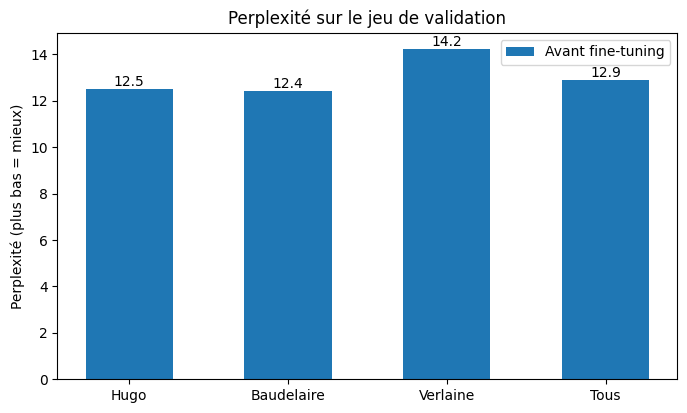

In [ ]:
import math
import numpy as np
from collections import defaultdict

def perplexite_par_auteur(dataset, modele):
    modele.eval()
    nll, n_tok = defaultdict(float), defaultdict(int)
    for ex in dataset:
        msgs = ex["messages"]
        prompt_txt = tokenizer.apply_chat_template(msgs[:1], tokenize=False, add_generation_prompt=True)
        full_txt = tokenizer.apply_chat_template(msgs, tokenize=False)
        n_prompt = len(tokenizer(prompt_txt, add_special_tokens=False)["input_ids"])
        ids = tokenizer(full_txt, add_special_tokens=False, return_tensors="pt")["input_ids"].to("cuda")

        labels = ids.clone()
        labels[:, :n_prompt] = -100          # on ignore la consigne : seule la réponse compte
        with torch.no_grad():
            loss = modele(input_ids=ids, labels=labels).loss.item()

        n = ids.shape[1] - n_prompt          # nombre de tokens du poème
        for cle in (ex["auteur"], "Tous"):
            nll[cle] += loss * n
            n_tok[cle] += n
    return {cle: math.exp(nll[cle] / n_tok[cle]) for cle in nll}

def tracer_perplexite(avant, apres=None):
    groupes = ["Hugo", "Baudelaire", "Verlaine", "Tous"]
    x = np.arange(len(groupes))
    w = 0.38 if apres else 0.55
    fig, ax = plt.subplots(figsize=(8, 4.5))
    b1 = ax.bar(x - (w / 2 if apres else 0), [avant[g] for g in groupes], w, label="Avant fine-tuning")
    ax.bar_label(b1, fmt="%.1f")
    if apres:
        b2 = ax.bar(x + w / 2, [apres[g] for g in groupes], w, label="Après fine-tuning")
        ax.bar_label(b2, fmt="%.1f")
    ax.set_xticks(x)
    ax.set_xticklabels(groupes)
    ax.set_ylabel("Perplexité (plus bas = mieux)")
    ax.set_title("Perplexité sur le jeu de validation")
    ax.legend()
    plt.show()

ppl_avant = perplexite_par_auteur(val_ds, model)
print({k: round(v, 2) for k, v in ppl_avant.items()})
tracer_perplexite(ppl_avant)

# 4. Configuration de QLoRA et entraînement
Ajout des adaptateurs LoRA au modèle quantifié en 4 bits, puis entraînement sur la partie « réponse » uniquement (le poème).

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)
model.print_trainable_parameters()

Unsloth 2026.10.7 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


trainable params: 41,943,040 || all params: 7,289,966,592 || trainable%: 0.5754


In [ ]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
from unsloth.chat_templates import train_on_responses_only

def formater(ex):
    texte = tokenizer.apply_chat_template(ex["messages"], tokenize=False)
    # le tokenizer ajoutera lui-même le <s> de début : on évite le doublon
    return {"text": texte.removeprefix("<s>")}

train_txt = train_ds.map(formater, remove_columns=train_ds.column_names)
val_txt = val_ds.map(formater, remove_columns=val_ds.column_names)

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_txt,
    eval_dataset=val_txt,
    args=SFTConfig(
        dataset_text_field="text",
        max_seq_length=max_seq_length,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,      # taille de lot effective : 8
        num_train_epochs=2,
        learning_rate=2e-4,
        warmup_steps=5,
        lr_scheduler_type="linear",
        optim="adamw_8bit",
        weight_decay=0.01,
        fp16=not is_bfloat16_supported(),   # le T4 utilise fp16
        bf16=is_bfloat16_supported(),
        logging_steps=5,
        eval_strategy="steps",
        eval_steps=20,
        per_device_eval_batch_size=2,
        seed=3407,
        output_dir="outputs",
        report_to="none",
    ),
)

# La perte n'est calculée que sur le poème, pas sur la consigne
trainer = train_on_responses_only(
    trainer,
    instruction_part="[INST]",
    response_part="[/INST]",
)

# Vérification : ce que le modèle "apprend" doit être uniquement le poème
exemple = trainer.train_dataset[0]
appris = [t for t, l in zip(exemple["input_ids"], exemple["labels"]) if l != -100]
print(tokenizer.decode(appris)[:300])

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

Map:   0%|          | 0/45 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/527 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/45 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/527 [00:00<?, ? examples/s]

Map:   0%|          | 0/45 [00:00<?, ? examples/s]

Je suis l'Empire à la fin de la décadence,
Qui regarde passer les grands Barbares blancs
En composant des acrostiches indolents
D'un style d'or où la langueur du soleil danse.

L'âme seulette a mal au coeur d'un ennui dense.
Là-bas on dit qu'il est de longs combats sanglants.
O n'y pouvoir, étant si


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 527 | Num Epochs = 2 | Total steps = 132
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 41,943,040 of 7,289,966,592 (0.58% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
20,2.299193,2.304402
40,2.245120,2.274060
60,2.255386,2.255360
80,1.969518,2.285960
100,1.899160,2.277199
120,1.919450,2.265169
132,1.871452,2.266613


Filter:   0%|          | 0/45 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for MistralForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-132/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-132.


Durée : 24.3 minutes


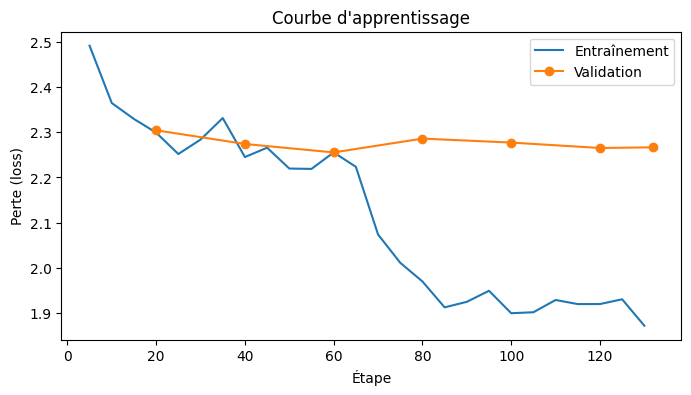

In [ ]:
stats = trainer.train()
print(f"Durée : {stats.metrics['train_runtime'] / 60:.1f} minutes")

# Courbe de perte (entraînement vs validation)
hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
va = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(8, 4))
plt.plot(*zip(*tr), label="Entraînement")
plt.plot(*zip(*va), marker="o", label="Validation")
plt.xlabel("Étape")
plt.ylabel("Perte (loss)")
plt.title("Courbe d'apprentissage")
plt.legend()
plt.show()

Unsloth: Restored added_tokens_decoder metadata in lora_poetes/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in lora_poetes.


Avant : {'Hugo': 12.49, 'Tous': 12.9, 'Baudelaire': 12.4, 'Verlaine': 14.22}
Après : {'Hugo': 9.02, 'Tous': 9.46, 'Baudelaire': 9.38, 'Verlaine': 10.31}


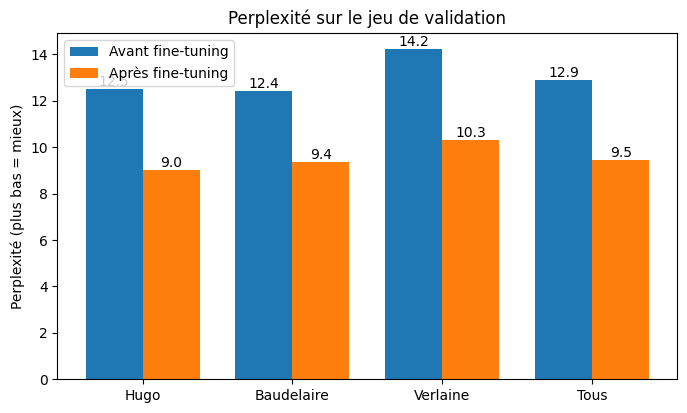

In [ ]:
# Sauvegarde immédiate des adaptateurs LoRA (quelques dizaines de Mo)
model.save_pretrained("lora_poetes")
tokenizer.save_pretrained("lora_poetes")

# Perplexité après entraînement, avec la même fonction qu'avant
ppl_apres = perplexite_par_auteur(val_ds, model)
print("Avant :", {k: round(v, 2) for k, v in ppl_avant.items()})
print("Après :", {k: round(v, 2) for k, v in ppl_apres.items()})
tracer_perplexite(ppl_avant, ppl_apres)

In [ ]:
import contextlib

FastLanguageModel.for_inference(model)   # mode inférence optimisé

corpus_train = "\n".join(p["texte"] for p in train)

def ecrire(consigne, avec_adaptateur=True, seed=0):
    ids = tokenizer.apply_chat_template(
        [{"role": "user", "content": consigne}],
        tokenize=True, add_generation_prompt=True, return_tensors="pt",
    ).to("cuda")
    torch.manual_seed(seed)
    ctx = contextlib.nullcontext() if avec_adaptateur else model.disable_adapter()
    with ctx:
        sortie = model.generate(input_ids=ids, max_new_tokens=300,
                                temperature=0.8, top_p=0.9, do_sample=True,
                                pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(sortie[0][ids.shape[1]:], skip_special_tokens=True).strip()

def vers_copies(poeme):
    vers = [l.strip() for l in poeme.split("\n") if len(l.strip()) > 25]
    copies = [v for v in vers if v in corpus_train]
    return len(copies), len(vers)

for auteur in ["Victor Hugo", "Charles Baudelaire", "Paul Verlaine"]:
    consigne = f"Écris un poème dans le style de {auteur}. Sujet : la mer."
    for etiquette, actif in [("AVANT", False), ("APRÈS", True)]:
        poeme = ecrire(consigne, avec_adaptateur=actif)
        c, n = vers_copies(poeme)
        print("=" * 60)
        print(f"{auteur} - {etiquette}  (vers copiés du dataset : {c}/{n})")
        print(poeme)

Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Victor Hugo - AVANT  (vers copiés du dataset : 0/19)
Sur les bords de ce monde immense,

Où les vents meurent et naissent,

L'océan, sombre et effrayant,

A son souffle me dorent.

Les nuages se meuvent dans ses bras,

Et ses yeux, pleins de rêves,

Regardent le ciel sans fin,

Et m'accusent de mes peines.

Le sable blanc et les pierres,

Sont les ossements de ses anciens dieux,

Qui, à l'aube des temps, ont brûlé

Leur essence dans ses flammes.

L'horloge sonne sans fin,

Et le temps coule sans arrêt,

Mais l'océan, dans son repos,

Est la vie et la mort en même temps.

Il pleure les larmes de ses vagues,

Et ses pleurs sont les sons

D'une éternité qui,

Nous entendra au-delà des tombes.

O mer, mer, ô ma mère,

Tu es le seul qui me soigne,

Tu es le seul qui me parle,

Et ton sou


Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Victor Hugo - APRÈS  (vers copiés du dataset : 0/17)
C'est la mer.
Et le vent a tous les tons de la musique.
Elle est profonde et verte comme la nuit;
Elle a les pleurs de l'infini en ses yeux;
Elle est une âme éternelle et secrète;
Elle est l'occident, l'azur, le jour, le ciel;
La nature est toute en elle, l'ombre et la lumière;
Elle est la terre, elle est l'azur; la mer!
Tout est en elle; la mer! on sent que c'est Dieu!
Le soir, elle est en deuil; le matin, elle est blanche;
Son front a l'éclair; son flanc a la brume;
Le vent la déchire et l'onde la tond;
C'est un énorme front de nuages qui sombre;
Elle est la mer, elle est le grand mur sombre,
L'horizon où nous voyons la fin du monde.

Ainsi parle-t-il, à l'heure où l'on voit le jour
Commencer à prendre une haute forme étrange,
Et l'ombre, en se relevant, s'étirer en rang


Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Charles Baudelaire - AVANT  (vers copiés du dataset : 0/16)
Dans les yeux du monde, la mer, la marée noire,

Un spectacle sans fin, où les dieux de l'oubli

Dansent au rythme de la tempête et du calme,

Un ballet de vagues et de nuages errants.

Une sirène, dans sa nuit de corail,

A son chant, éveille le sommeil des abysses,

Et ses larmes, qui sont des perles de cristal,

Aimées des aventuriers, et des pêcheurs, et des poètes.

La mer, comme un vampire, se nourrit de la terre,

Son regard, un abyssus, dans lequel nous sommes perdus,

Et nous offre, dans ses bras, une mort éternelle,

Une mort qui est aussi une vie, comme un songe.

Et nous, nous sommes ses esclaves, et ses amants,

Et nous, nous sommes ses martyrs, et ses victimes,

Et nous, nous sommes ses enfants, et ses maîtres,

Et nous, nous sommes ses poètes, et ses mots.

Charles Baudelaire,


Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Charles Baudelaire - APRÈS  (vers copiés du dataset : 0/17)
C'est une blancheur immense, une splendeur immense,
Un étendue monstrueuse, effrayante, sublime;
La mer n'est pas une chose comme une autre chose,
C'est l'univers, la terre entière et le ciel immense.

Elle est l'éternel souffle du démon des flots,
Le souffle de l'espace, du temps et du néant,
C'est la face sauvage et démoniaque de Dieu,
C'est la voix du vent, c'est la voix de l'abîme!

Tout en nous se révèle, par son éclair de tonnerre,
Son affreux et terrible éclat de beauté;
Puisqu'elle est le monde, c'est le grand énigmatique;

Et nous, comme un vieux marin qui se repent,
Quand nous nous apercevons de ce qu'elle est,
Nous craignons, nous reculons, et nous périssons.

La mer est un être vivant, un être incompréhensible
Qui se déplace et qui meurt en grand spectacle;
Elle s'ouvre et se referme


Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Paul Verlaine - AVANT  (vers copiés du dataset : 0/16)
Dans les yeux du ciel, un gisant immense,

L'océan, l'océan, mon amour, mon amour.

Le soleil le brille, le vent le faufile,

Un murmure secret, un souffle amoureux.

Les vagues, elles montent, elles descendent,

Une émotion profonde, une douleur obscure.

Elles murmurent des mots qu'on ne comprend,

Elles parlent à l'âme, elles parlent au cœur.

Les étoiles, elles regardent du haut des nuages,

Et l'océan, il répond à leurs lointains regards.

Il murmure des secrets, il chante des aubades,

Il parle à l'âme, il parle au cœur.

L'océan, l'océan, mon amour, mon amour,

Et je suis un flotteur, un flotteur sans fin.

Je vais vers toi, ô mer, ô mer, ô mer,

Je vais vers toi, ô mer, ô mer, ô mer.
Paul Verlaine - APRÈS  (vers copiés du dataset : 0/12)
C'est la mer.
Et le vent a tous les tons de la musique
Et l'onde, en souriant, en riant, en chantant,
Fait un son d'orchestre vif et charmant.

C'est la mer.
Vous vous endormez, l'oeil sere

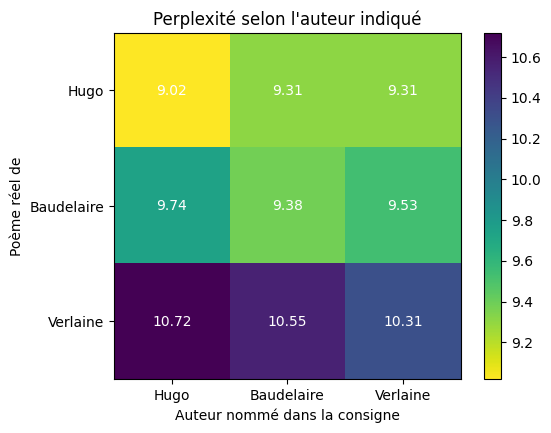

Bon auteur : 9.57 | mauvais auteur : 9.86


In [ ]:
FastLanguageModel.for_training(model)   # on repasse en mode calcul de perte

auteurs = ["Hugo", "Baudelaire", "Verlaine"]
matrice = np.zeros((3, 3))   # lignes : auteur réel ; colonnes : auteur nommé dans la consigne

for j, nomme in enumerate(auteurs):
    modifies = []
    for ex in val_ds:
        msgs = [dict(m) for m in ex["messages"]]
        msgs[0]["content"] = msgs[0]["content"].replace(NOMS[ex["auteur"]], NOMS[nomme])
        modifies.append({"messages": msgs, "auteur": ex["auteur"]})
    res = perplexite_par_auteur(modifies, model)
    for i, reel in enumerate(auteurs):
        matrice[i, j] = res[reel]

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(matrice, cmap="viridis_r")
ax.set_xticks(range(3)); ax.set_xticklabels(auteurs)
ax.set_yticks(range(3)); ax.set_yticklabels(auteurs)
ax.set_xlabel("Auteur nommé dans la consigne")
ax.set_ylabel("Poème réel de")
ax.set_title("Perplexité selon l'auteur indiqué")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{matrice[i, j]:.2f}", ha="center", va="center", color="white")
plt.colorbar(im)
plt.show()

diag = np.mean(np.diag(matrice))
hors_diag = np.mean(matrice[~np.eye(3, dtype=bool)])
print(f"Bon auteur : {diag:.2f} | mauvais auteur : {hors_diag:.2f}")

## 5. Évaluation

**Perplexité sur le jeu de validation (45 extraits inédits)**

| | Hugo | Baudelaire | Verlaine | Ensemble |
|---|---|---|---|---|
| Avant fine-tuning | 12,5 | 12,4 | 14,2 | 12,9 |
| Après fine-tuning | 9,0 | 9,4 | 10,3 | 9,5 |

La perplexité baisse d'environ **26 %**. Aucun vers du jeu d'entraînement n'est recopié littéralement dans les six poèmes générés.

**Test de conditionnement par auteur.** Pour chaque poème de validation, on calcule la perplexité en nommant soit le vrai auteur, soit un autre. La perplexité est plus basse avec le bon auteur pour les trois poètes (9,57 en moyenne contre 9,86 avec un mauvais auteur, soit ≈ 3 %). Le modèle a donc surtout appris un registre poétique général du XIXᵉ siècle, et seulement faiblement les voix individuelles.

**Limites**
- Jeu de validation de petite taille (15 extraits par auteur), un seul entraînement.
- Les extraits d'un même long poème (*La Légende des siècles*) peuvent se retrouver à la fois dans l'entraînement et la validation.
- La perplexité ne mesure ni les rimes, ni le mètre, ni la qualité littéraire : le modèle écrit rarement en alexandrins rimés.
- Pas d'évaluation humaine.

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("lora_poetes", "zip", "lora_poetes")
files.download("lora_poetes.zip")      # adaptateurs LoRA (quelques centaines de Mo au plus)
files.download("data/train.jsonl")
files.download("data/val.jsonl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Conclusions et pistes d'amélioration

### Ce que montre l'expérience
- Le fine-tuning QLoRA de **Mistral 7B Instruct v0.3**, sur un GPU T4 gratuit, fait baisser la perplexité de validation de **12,9 à 9,5** (≈ -26 %), pour les trois poètes.
- Les poèmes générés adoptent un vocabulaire et des tournures plus proches du XIXᵉ siècle (anaphores, images de l'abîme, de l'infini) et une vraie structure en strophes.
- Aucun vers du jeu d'entraînement n'est recopié littéralement dans les poèmes testés.
- Le nom de l'auteur dans la consigne est utilisé par le modèle, mais **faiblement** (perplexité de 9,57 avec le bon auteur contre 9,86 avec un mauvais) : le modèle a surtout appris un registre poétique général, pas trois voix distinctes.

### Limites
- Petit jeu de validation (15 extraits par auteur) et un seul entraînement.
- Possible fuite entre entraînement et validation pour les longs poèmes de *La Légende des siècles*.
- Peu de rimes et pas d'alexandrins réguliers : la perplexité ne mesure pas la versification.
- Sujets des consignes générés automatiquement, donc parfois approximatifs.
- Aucune évaluation humaine.

### Pistes d'amélioration
1. Se concentrer sur **un seul auteur** pour une voix plus nette.
2. Augmenter le corpus (autres recueils de Hugo, Baudelaire, Verlaine).
3. Mesurer la versification (syllabes, rimes) et pas seulement la perplexité.
4. Entraîner une seule epoch : la seconde n'a presque rien apporté.
5. Comparer avec d'autres modèles (Qwen3 8B, Llama 3.1 8B) ou avec une version Base.

### Ce que j'ai appris
La préparation des données est l'étape qui prend le plus de temps et qui pèse le plus sur le résultat. Mesurer ce que le modèle a vraiment appris, y compris avec un résultat modeste, est plus utile que de le présenter comme un succès.